In [1]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
from global_land_mask import globe
import matplotlib.dates as mdates

# Loading Data

In [2]:
ens = xr.open_dataset('ensemble_data_stereo_coords.nc')
ens = ens.compute()

In [3]:
# making sure that ice data has the same time index as the ensemble data
ice_dum = xr.open_dataset('ice_data.nc')
ice_dum = ice_dum.sel(time=slice('2023-05-08','2023-06-13'))

start = ice_dum.time.values[0]
end = ice_dum.time.values[-1] + pd.Timedelta(hours=23)   # include all 24 hours of the last day

hourly_times = pd.date_range(start, end, freq="1h")

ice = ice_dum.reindex(time=hourly_times, method="ffill")

ice = ice.drop_sel(time='2023-05-24 01:00:00') # missing from ens dataset

ice = ice.rename({'time':'launch_time'})

# Defining the masking functions

In [4]:
"""
Ice masking functions
"""

def closest_icecoord(value, search_array):   
    """
    Find the closest value in a given array (search_array) to a single value given by the user (x).
    For use in conjunction with apply_ufunc.
    Inputs:
    - values: the array of values that you want to 
    - search_array: the array that contains the values that you want to find the closest value of.
    Outputs:
    - an array 
    """
    value_dif = np.abs(value - search_array)
    closest_value = search_array[np.argmin(value_dif)]
    return closest_value

def determine_ice_coord(closest_x, closest_y, ice_data):
    """
    Determine the ice coodrdinate at that location from the ice data.
    Inputs:
    - closest_x, closest_y: the closest x and y coordinates held in the ice data netCDF file.
    Outputs:
    - z: the ice coordinate that corresponds to these coordinates.
    """
    z = ice_data['z'].sel(x=closest_x, y=closest_y).values
    return z

def ice_interpolation(x,y):
    """
    Finding the squared distance of an x-y coordinate in the stereographic projection from the origin (which is 0,0).
    """
    return np.sqrt(x**2 + y**2)

def ice_mask(closest_x, closest_y, z, thresh):
    """
    Actually perform the ice masking. If the coordinate is within a certain radiaus and is NaN, assume it is ice (fill in the hole at the North Pole
    from the satellite data), and if not return a 1 if it is sufficiently icy (75% ice) and a 0 if it is not!
    Inputs:
    - closest_x, closest_y, the closest ice coordinate to the trajectory coordinate.
    - z: the corresponding ice coordinate
    Outputs:
    - 1 if attributed to sea-ice, 0 if not sea-ice.
    """
    near_pole = ice_interpolation(closest_x, closest_y) < 325052.227135
   # pole_hole = near_pole & np.isnan(z)
    return (near_pole | (z >= thresh)).astype(int)

"""
Land masking functions
"""

def land_mask(lat, lon):
    """
    Check if a coordinate is land or not using global-land-mask. Global-land-mask cannot be vectorized.
    Inputs:
    - lat, lon: the latitude and longitude coordinate of the point in question
    Outputs:
    - 1 if land and 0 if ocean.
    """
    mask = globe.is_land(lat, lon)
    return mask.astype(int)

"""
Boundary layer masking function
"""

def bl_mask(alt, bl_height):
    """
    Mask to see if the air parcel is above or below the boundary layer.
    Inputs:
    - alt, the simulated altitude of the air parcel
    - bl_height: the simulated altitude of the boundary layer height
    Returns:
    - mask of same dimensions as inputs with 1 where alt > bl_height and 0 otherwise.
    """
    mask = (alt  > bl_height)
    return mask.astype(int)

# Applying the Masks

In [5]:
# find the closest sea-ice coordinate to each trajectory coordinate, slightly slow ~ 20 seconds.

closest_x = xr.apply_ufunc(
    closest_icecoord,
    ens['x_stereo'],                        
    kwargs={"search_array": ice_dum.x.values},
    vectorize=True,                
    dask="parallelized",           
    output_dtypes=[ice_dum.x.values.dtype],
)

closest_y = xr.apply_ufunc(
    closest_icecoord,
    ens['y_stereo'],
    kwargs={"search_array": ice_dum.y.values},
    vectorize=True,
    dask='parallelized',
    output_dtypes=[ice_dum.y.values.dtype],
)

ens['closest_x'] = closest_x
ens['closest_y'] = closest_y

In [6]:
# selecting the closest ice percentage for that trajectory coordinate location and time
z = ice['z'].sel(x=ens['closest_x'], y=ens['closest_y'])
ens['z'] = z
ens = ens.drop_vars(['x','y'])

In [7]:
# applying the ice mask, quite slow ~ 2 mins
ens['icemask'] = ice_mask(ens['closest_x'], ens['closest_y'], ens['z'], 75)

In [8]:
# applying the land-ocean mask, quite slow ~ 2 mins 22 secs
landmask = xr.apply_ufunc(
    land_mask,
    ens['lat'],
    ens['lon'],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[int],
)

ens['landmask'] = landmask

In [9]:
# applying the boundary layer mask (should happen last, if it is above the boundary layer we don't care what surface type it is over)
blmask = bl_mask(ens['alt'], ens['bl_height'])
ens['blmask'] = blmask

In [10]:
# imposting heirarchy of booleans (making sure that there are no overlapping 1s or 0s)
# in original code, order was BL then ice then land then sea
ens['icemask'] = xr.where(ens['blmask'] == 1, 0, ens['icemask']) # if above boundary layer return 0
ens['landmask'] = xr.where((ens['icemask'] == 1) | (ens['blmask'] == 1), 0, ens['landmask']) # if above boundary layer or determined as ice, return 0
ens['seamask'] = xr.where((ens['landmask']==0) & (ens['icemask']==0) & (ens['blmask'] == 0), 1, 0) # everything else is ocean

In [11]:
# checking the mask has only 1 1 and everything else is zero:
((ens['blmask'] + ens['icemask'] + ens['landmask'] + ens['seamask']) == 1).all()

<xarray.DataArray ()> Size: 1B
array(True)

# Calculating and plotting the contributions from different surface types

In [12]:
ens['mean_precip'] = ens['precip'].mean(dim='ens_member')

In [13]:
traj_length = 7 # how many days back in time you care about

In [14]:
# recreating the contribution over time for the different surface types to the ensemble of back trajectories:
contributions = xr.Dataset(coords={'launch_time':ens.sel(traj_step=slice(0, 24*traj_length)).launch_time})
surf = ['land', 'ice', 'sea', 'bl']
for s in surf:
    mask = f'{s}mask'
    total = (traj_length*24 + 1) * 27 # (time steps * ensemble members)
    contributions[f'{s}_%'] = ( ens[mask].sel(traj_step = slice(0, 24*traj_length)).sum(dim=['ens_member', 'traj_step']) / total )*100
contributions['precip_mm/hr'] = ens['mean_precip'].sel(traj_step=slice(0, 24*traj_length)).sum(dim='traj_step')

In [15]:
contributions['total'] = contributions['land_%'] + contributions['ice_%'] + contributions['sea_%'] + contributions['bl_%']
mask = ~np.isclose(contributions['total'], 100) 
np.sum(mask) # checking that the contributions sum to 100 % per back trajectory launch time

np.int64(0)

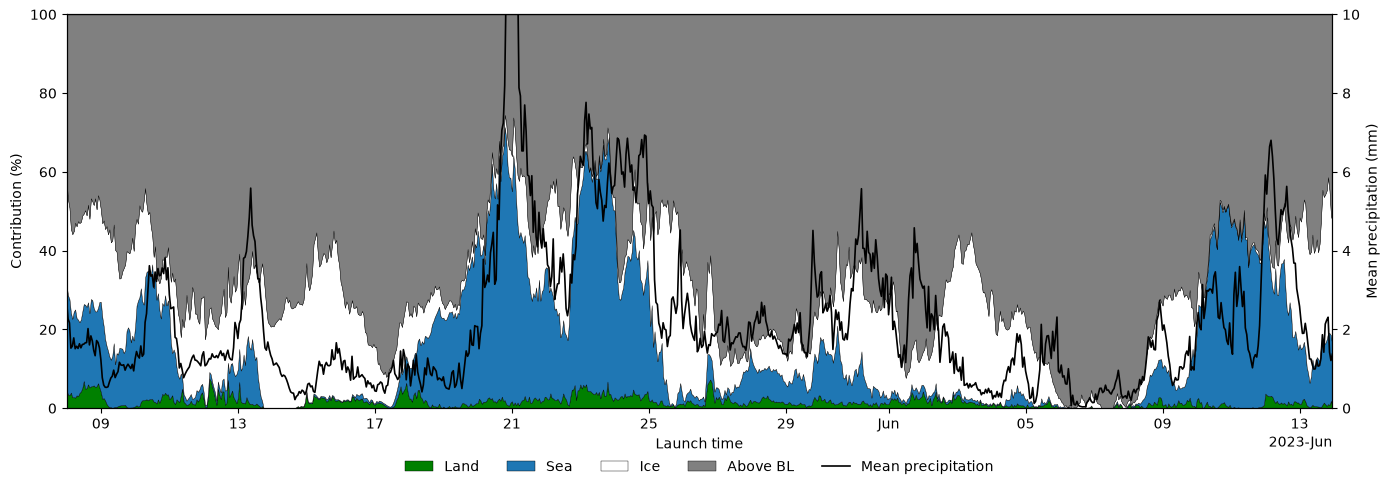

In [18]:
# plotting, claude wrote this code block.

layers = [           
    ("land_%", "Land",     "green"),
    ("sea_%",  "Sea",      "tab:blue"),
    ("ice_%",  "Ice",      "white"),
    ("bl_%",   "Above BL", "grey"),
]

times = contributions["launch_time"].values

fig, ax = plt.subplots(figsize=(14, 5))

ax.stackplot(
    times,
    *[contributions[var].values for var, _, _ in layers],
    labels=[label for _, label, _ in layers],
    colors=[colour for _, _, colour in layers],
    edgecolor="black",
    linewidth=0.3,
)

ax.set_xlim(times[0], times[-1])
ax.set_ylim(0, 100)
ax.set_ylabel("Contribution (%)")
ax.set_xlabel("Launch time")

# Precipitation on a second y-axis
ax2 = ax.twinx()
ax2.plot(times, contributions["precip_mm/hr"].values,
         color="black", linewidth=1.2, label="Mean precipitation")
ax2.set_ylabel("Mean precipitation (mm)")   # change units to match your data
ax2.set_ylim(0, 10)

handles1, labels1 = ax.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()

handles = handles1 + handles2
labels = labels1 + labels2
ax.legend(handles, labels,
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=len(labels), frameon=False)

locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.tight_layout()
plt.show()

In [19]:
# saving data as a csv overview:

contributions.drop_vars('total').to_dataframe().to_csv('ens_7days_recent.csv')

# Adding metadata and formatting NetCDF File

In [20]:
ens = ens.drop_vars('mean_precip')

In [57]:
ens

<xarray.Dataset> Size: 952MB
Dimensions:      (launch_time: 887, traj_step: 241, ens_member: 27)
Coordinates:
  * launch_time  (launch_time) datetime64[ns] 7kB 2023-05-08 ... 2023-06-13T2...
  * traj_step    (traj_step) int32 964B 0 1 2 3 4 5 ... 235 236 237 238 239 240
  * ens_member   (ens_member) int32 108B 1 2 3 4 5 6 7 ... 21 22 23 24 25 26 27
Data variables: (12/22)
    traj_time    (launch_time, traj_step, ens_member) datetime64[ns] 46MB 202...
    lat          (launch_time, traj_step, ens_member) float64 46MB 78.14 ... ...
    lon          (launch_time, traj_step, ens_member) float64 46MB 15.4 ... -...
    alt          (launch_time, traj_step, ens_member) float64 46MB 270.0 ... ...
    pressure     (launch_time, traj_step, ens_member) float64 46MB 935.4 ... ...
    bl_height    (launch_time, traj_step, ens_member) float64 46MB 36.8 ... 2...
    ...           ...
    closest_y    (launch_time, traj_step, ens_member) float64 46MB -6.344e+05...
    z            (launch_time, traj_step, ens_member) float32 23MB nan ... 96.31
    icemask      (launch_time, traj_step, ens_member) int64 46MB 0 0 0 ... 0 0 0
    landmask     (launch_time, traj_step, ens_member) int64 46MB 0 0 1 ... 0 0 0
    blmask       (launch_time, traj_step, ens_member) bool 6MB True ... True
    seamask      (launch_time, traj_step, ens_member) int64 46MB 0 0 0 ... 0 0 0